<a href="https://colab.research.google.com/github/jaroslav200720072007-beep/Orders_Data_Analysis/blob/main/Orders_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import kagglehub
import zipfile
import os
import shutil
path = kagglehub.dataset_download("ankitbansal06/retail-orders")

100%|██████████| 200k/200k [00:00<00:00, 61.7MB/s]

Extracting files...


In [3]:
from google.colab import files
files.upload()   # у вікні виберіть kaggle.json із «Загрузок»

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"dxfcgh","key":"dc3bf11393f85f6b1078319f870d6bdc"}'}

In [4]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# те саме, що у відео
!kaggle datasets download ankitbansal06/retail-orders -f orders.csv

Dataset URL: https://www.kaggle.com/datasets/ankitbansal06/retail-orders
License(s): CC0-1.0
100% 200k/200k [00:00<00:00, 90.4MB/s]



In [5]:
import zipfile

zip_ref = zipfile.ZipFile('orders.csv.zip')
zip_ref.extractall()
zip_ref.close()

In [6]:
import os
print(os.listdir(path))   # має бути orders.csv

['orders.csv']


In [7]:
import pandas as pd
df = pd.read_csv('orders.csv')
df.head()

,Order Id,Order Date,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub Category,Product Id,cost price,List Price,Quantity,Discount Percent
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5


In [8]:
df.columns

Index(['Order Id', 'Order Date', 'Ship Mode', 'Segment', 'Country', 'City',
       'State', 'Postal Code', 'Region', 'Category', 'Sub Category',
       'Product Id', 'cost price', 'List Price', 'Quantity',
       'Discount Percent'],
      dtype='object')

In [9]:
df['Ship Mode'].value_counts()

,count
Ship Mode,
Standard Class,5962
Second Class,1945
First Class,1538
Same Day,543
Not Available,4
unknown,1


In [10]:
df.isna().sum()

,0
Order Id,0
Order Date,0
Ship Mode,1
Segment,0
Country,0
City,0
State,0
Postal Code,0
Region,0
Category,0


In [11]:
df.rename(columns = {'Order Id': 'order_id',
                     'City': 'city',
                     })

,order_id,Order Date,Ship Mode,Segment,Country,city,State,Postal Code,Region,Category,Sub Category,Product Id,cost price,List Price,Quantity,Discount Percent
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,2023-02-18,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,FUR-FU-10001889,30,30,3,4
9990,9991,2023-03-17,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,FUR-FU-10000747,70,90,2,4
9991,9992,2022-08-07,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,TEC-PH-10003645,220,260,2,2
9992,9993,2022-11-19,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,OFF-PA-10004041,30,30,4,3


In [12]:
df.columns = df.columns.str.lower()
df.columns

Index(['order id', 'order date', 'ship mode', 'segment', 'country', 'city',
       'state', 'postal code', 'region', 'category', 'sub category',
       'product id', 'cost price', 'list price', 'quantity',
       'discount percent'],
      dtype='object')

In [13]:
##Розрахунок знижки
df['discount'] = df['list price']*df['discount percent']*0.01
df

,order id,order date,ship mode,segment,country,city,state,postal code,region,category,sub category,product id,cost price,list price,quantity,discount percent,discount
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2,5.2
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3,21.9
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5,0.5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2,19.2
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,2023-02-18,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,FUR-FU-10001889,30,30,3,4,1.2
9990,9991,2023-03-17,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,FUR-FU-10000747,70,90,2,4,3.6
9991,9992,2022-08-07,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,TEC-PH-10003645,220,260,2,2,5.2
9992,9993,2022-11-19,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,OFF-PA-10004041,30,30,4,3,0.9


In [14]:
##Ціна продажу
df['sale_price'] = df['list price'] - df['discount']
df

,order id,order date,ship mode,segment,country,city,state,postal code,region,category,sub category,product id,cost price,list price,quantity,discount percent,discount,sale_price
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2,5.2,254.8
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3,21.9,708.1
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5,0.5,9.5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2,19.2,940.8
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5,1.0,19.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,2023-02-18,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,FUR-FU-10001889,30,30,3,4,1.2,28.8
9990,9991,2023-03-17,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,FUR-FU-10000747,70,90,2,4,3.6,86.4
9991,9992,2022-08-07,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,TEC-PH-10003645,220,260,2,2,5.2,254.8
9992,9993,2022-11-19,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,OFF-PA-10004041,30,30,4,3,0.9,29.1


In [15]:
##Прибуток
df['profit'] = df['sale_price'] - df['cost price']
df

,order id,order date,ship mode,segment,country,city,state,postal code,region,category,sub category,product id,cost price,list price,quantity,discount percent,discount,sale_price,profit
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2,5.2,254.8,14.8
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3,21.9,708.1,108.1
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5,0.5,9.5,-0.5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2,19.2,940.8,160.8
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5,1.0,19.0,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,2023-02-18,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,FUR-FU-10001889,30,30,3,4,1.2,28.8,-1.2
9990,9991,2023-03-17,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,FUR-FU-10000747,70,90,2,4,3.6,86.4,16.4
9991,9992,2022-08-07,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,TEC-PH-10003645,220,260,2,2,5.2,254.8,34.8
9992,9993,2022-11-19,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,OFF-PA-10004041,30,30,4,3,0.9,29.1,-0.9


In [16]:
df.dtypes

,0
order id,int64
order date,object
ship mode,object
segment,object
country,object
city,object
state,object
postal code,int64
region,object
category,object


In [17]:
df['order date'] = pd.to_datetime(df['order date'])
df.dtypes

,0
order id,int64
order date,datetime64[ns]
ship mode,object
segment,object
country,object
city,object
state,object
postal code,int64
region,object
category,object


In [18]:
df.columns = df.columns.str.replace(' ', '_')

In [19]:
df.drop(columns=['list_price', 'cost_price', 'discount_percent'], inplace=True)

In [20]:
import sqlite3

conn = sqlite3.connect('retail.db')
df.to_sql('orders', conn, if_exists='replace', index=False)
conn.close()
print("Дані успішно збережено в базу даних!")

from google.colab import files
files.download('retail.db')

Дані успішно збережено в базу даних!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
df

,order_id,order_date,ship_mode,segment,country,city,state,postal_code,region,category,sub_category,product_id,quantity,discount,sale_price,profit
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,2,5.2,254.8,14.8
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,3,21.9,708.1,108.1
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,2,0.5,9.5,-0.5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,5,19.2,940.8,160.8
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,2,1.0,19.0,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,2023-02-18,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,FUR-FU-10001889,3,1.2,28.8,-1.2
9990,9991,2023-03-17,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,FUR-FU-10000747,2,3.6,86.4,16.4
9991,9992,2022-08-07,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,TEC-PH-10003645,2,5.2,254.8,34.8
9992,9993,2022-11-19,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,OFF-PA-10004041,4,0.9,29.1,-0.9


Text(0.5, 1.0, 'Розподіл Категорій Товару')

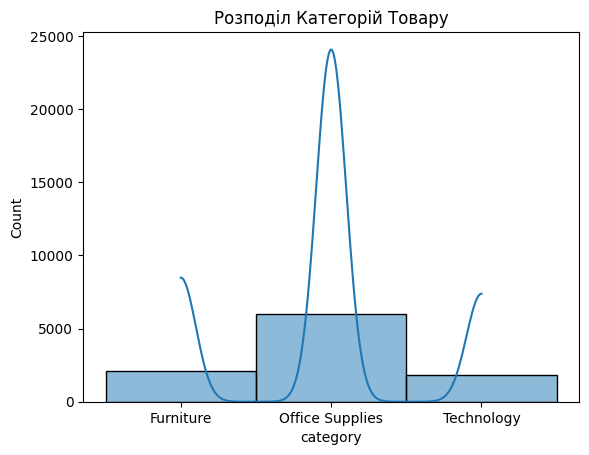

In [28]:
sns.histplot(df['category'], bins = 30, kde=True)
plt.title('Розподіл Категорій Товару')

[]

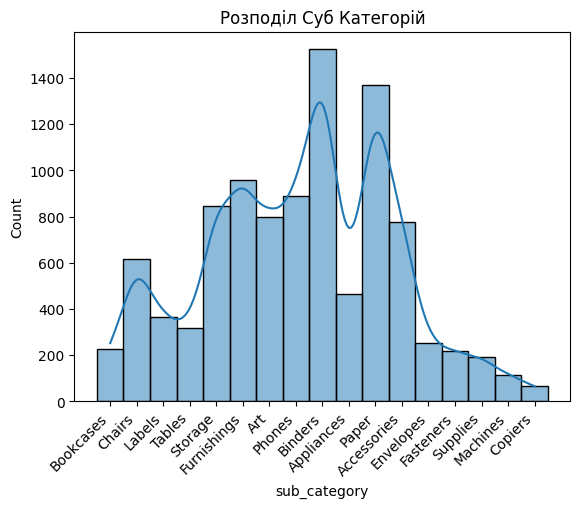

In [29]:
sns.histplot(df['sub_category'], bins=30, kde=True)
plt.xticks(rotation=45, ha='right')
plt.title('Розподіл Суб Категорій')
plt.plot()

<Axes: xlabel='category', ylabel='profit'>

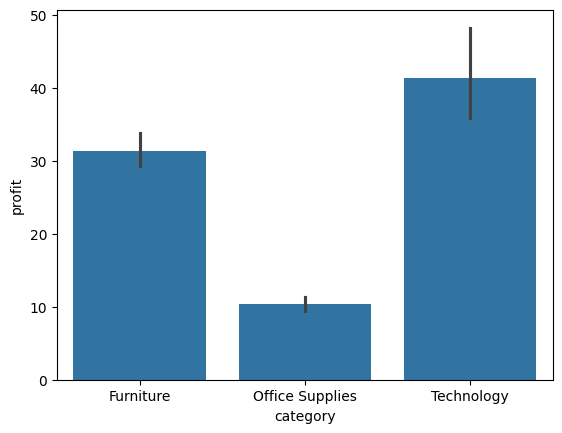

In [31]:
sns.barplot(x = 'category', y = 'profit', data=df)
plt.title('Дохід По Категоріях')
plt.show()

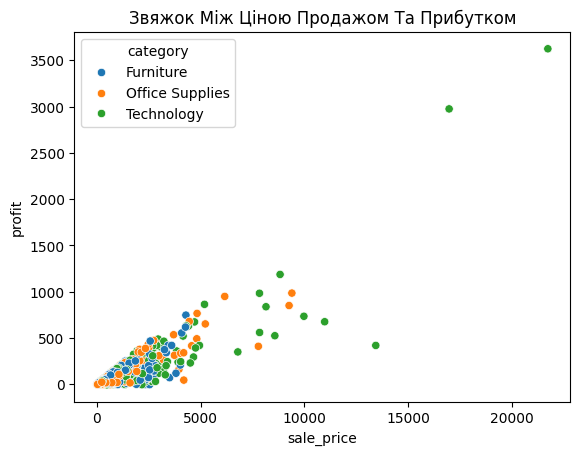

In [34]:
sns.scatterplot(x='sale_price', y='profit', hue='category', data=df)
plt.title('Звяжок Між Ціною Продажом Та Прибутком')
plt.show()

<Axes: xlabel='category', ylabel='profit'>

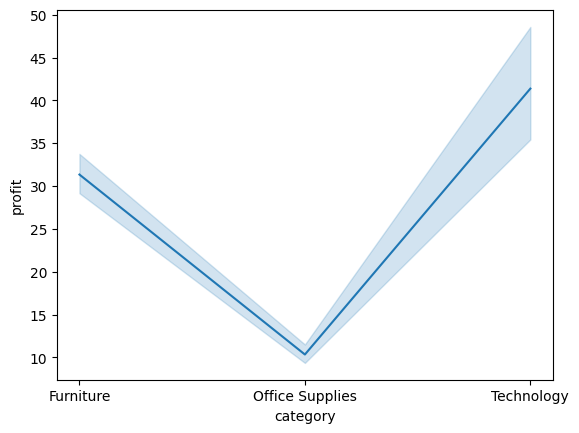

In [40]:
sns.lineplot(x = df['category'],y = df['profit'], data=df)

<Axes: xlabel='order_date', ylabel='profit'>

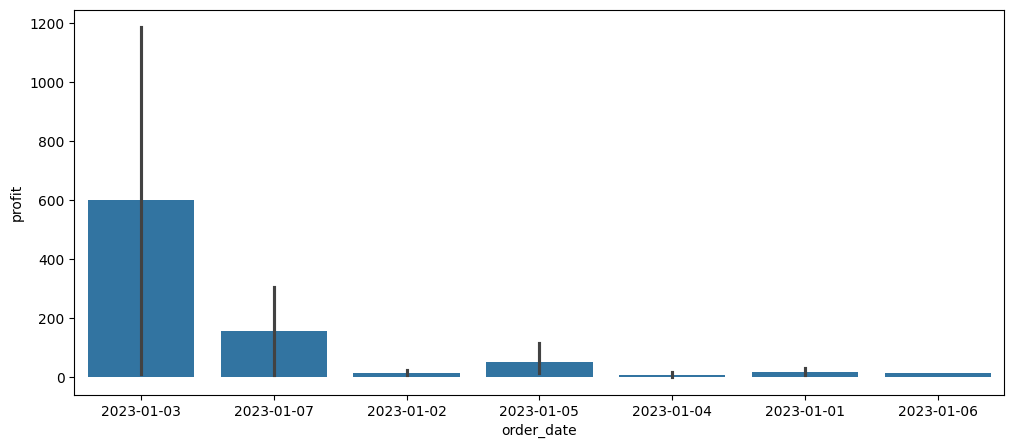

In [58]:
plt.figure(figsize=(12, 5))
filter_data = df.query("order_date >= '2023-01-01' and order_date <= '2023-01-07' and category == 'Technology' and country == 'United States'")
sns.barplot(x = 'order_date', y = 'profit', data=filter_data)


<Axes: >

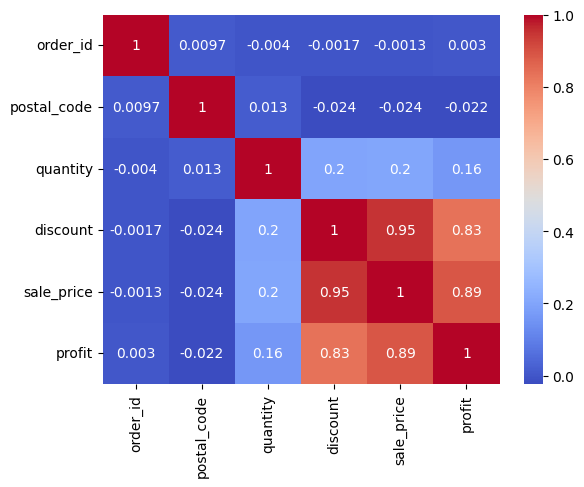

In [62]:
numeric_df = df.select_dtypes(include=['number'])
corr_numeric_df = numeric_df.corr()
sns.heatmap(corr_numeric_df, annot=True, cmap='coolwarm')